# Figure 2E — Where metapredict V3 struggles: the five worst-predicted CAID3 proteins

The CAID3 Disorder-PDB proteins on which metapredict V3 has the lowest per-protein AUC, each shown as four tracks: (1) metapredict V3 score with its predicted IDRs shaded, (2) the top CAID3 methods PUNCH2, SPOT-Disorder2 and AlphaFold-rsa (colours as in panel B), (3) PDB structural evidence (resolved as a monomer, as a homo-oligomer or only in a hetero-complex, in dark to light grey; in a construct but with missing density, hatched orange; not in any structure, hatched grey), and (4) the Disorder-PDB reference labels (colours as in panel C). Each protein is headed by its DisProt ID and metapredict V3 per-protein AUC. The PDB codes behind each resolved block are printed below rather than written on the figure. Track names and the legend are on panel D, which sits to the left with the same tracks.

**How it is made.** Per-protein AUC of metapredict V3 (3.1.0) is computed over each target's scored residues. Only targets of 40–500 residues with at least 15 disordered and 15 ordered scored residues are considered, so every example has a real mix of order and disorder. Structural coverage comes from DisProt → SIFTS → PDBe (`data/pdb_cache` in the shared data directory, built by `data/pdb_cache_pipeline`).

**Output:** `figures/figure_2E.pdf`

In [1]:
from caid3_panels import load_predictions, load_reference
from figtools import apply_style, require_metapredict_3_1, save_panel
from ground_truth_panels import (OTHER_PREDICTORS, load_coverage, make_composite, print_pdb_codes,
                                 select_best_worst)

apply_style()
require_metapredict_3_1()
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

N_EXAMPLES = 5

metapredict 3.1.0+7.g7dcf52c.dirty from /Users/alex/Dropbox/WASHU/Holehouse/tools/metapredict/metapredict/metapredict (git 43b92cd)


In [2]:
reference = load_reference()
predictions = load_predictions(['Metapredict-v3'] + [name for name, _ in OTHER_PREDICTORS])
metapredict_v3 = predictions.pop('Metapredict-v3')
coverage, coverage_pdbs = load_coverage()

selection = select_best_worst(reference, metapredict_v3, n=N_EXAMPLES)[1]
for tid, auc in selection:
    print(f'{tid}: per-protein AUC = {auc:.3f}')
print('PDB codes behind each resolved block (1-based residues):')
print_pdb_codes(selection, coverage, coverage_pdbs)

DP04195: per-protein AUC = 0.402
DP04228: per-protein AUC = 0.424
DP04249: per-protein AUC = 0.459
DP04214: per-protein AUC = 0.475
DP04036: per-protein AUC = 0.496
PDB codes behind each resolved block (1-based residues):
DP04195: 228-272 homo-oligomer: 2LO0
DP04228: 232-348 homo-oligomer: 3B1S
DP04249: 289-421 homo-oligomer: 6RYK
DP04214: 1-86 monomer: 1W53, 2J6Z, 2J70; 87-87 homo-oligomer: 2J6Y
DP04036: 2-46 monomer: 4XM5; 52-53 hetero-complex only: 4XLG; 54-90 monomer: 4XM5; 91-91 hetero-complex only: 4XLG; 98-150 monomer: 4XM5; 157-226 monomer: 4XM5; 227-229 hetero-complex only: 4XLG; 233-236 hetero-complex only: 4XLG; 237-263 monomer: 4XM5; 269-303 monomer: 4XM5


Wrote figures/figure_2E.pdf


PosixPath('figures/figure_2E.pdf')

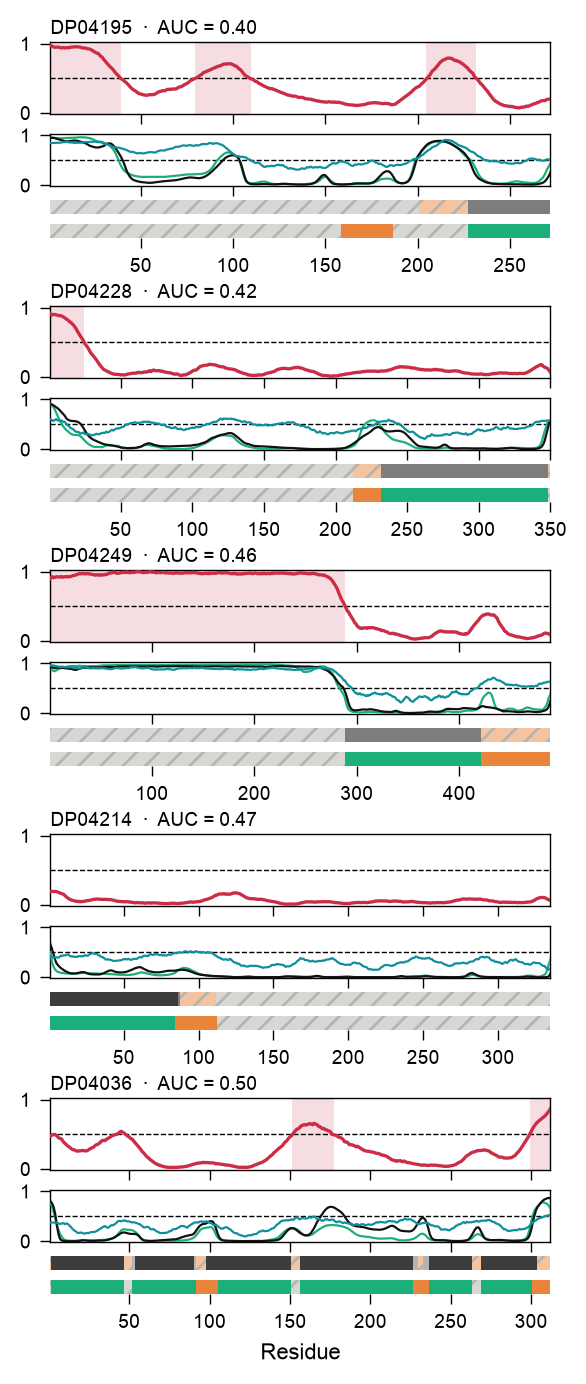

In [3]:
fig = make_composite(selection, reference, coverage, metapredict_v3, predictions, legend=False, track_labels=False)
save_panel(fig, 'figure_2E')